**TRABALHO 3: ALGORITMO DE DJIKSTRA**

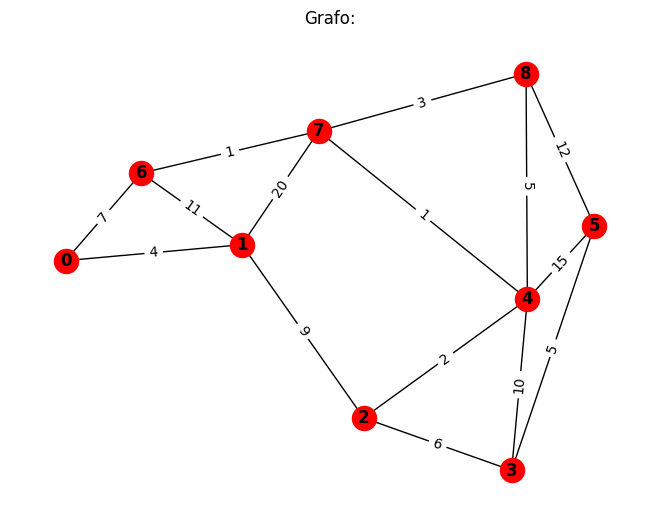

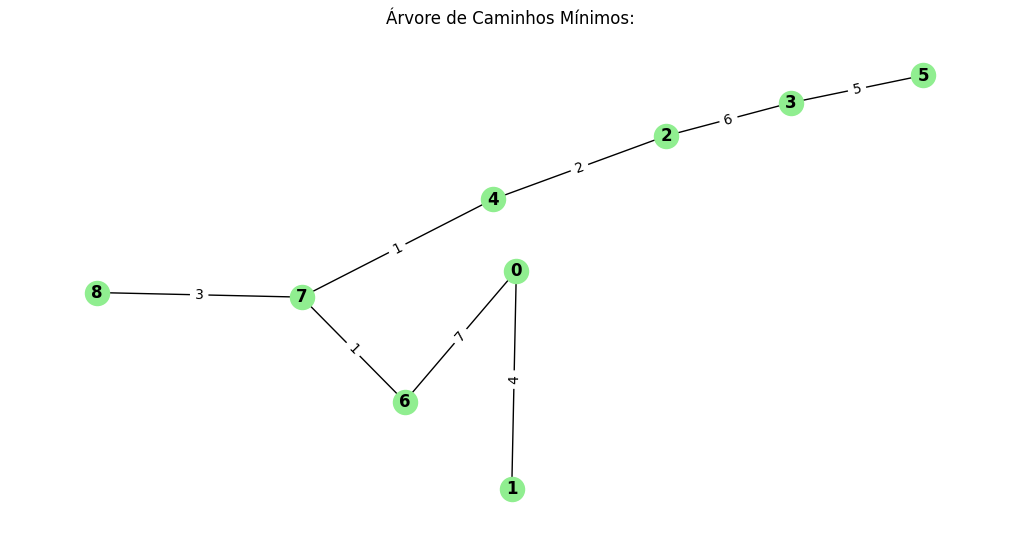

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

#Novo grafo
G = nx.Graph()

#Adiciona os vértices
G.add_nodes_from([0, 1, 2, 3, 4, 5, 6, 7, 8])

#Adiciona as arestas com peso, com raíz 0
G.add_weighted_edges_from([(0, 1, 4), (0, 6, 7), (1, 6, 11),
                           (1, 2, 9), (1, 7, 20), (6, 7, 1),
                           (7, 4, 1), (7, 8, 3), (4, 8, 5),
                           (4, 5, 15), (4, 3, 10), (4, 2, 2),
                           (2, 3, 6), (3, 5, 5), (8, 5, 12)])

# Desenha o grafo
pos = nx.spring_layout(G)
edge_labels = nx.get_edge_attributes(G, 'weight')
nx.draw(G, pos, with_labels=True, node_color='red', font_weight='bold') #Desenha vértices
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels) #Desenha arestas com peso
plt.title("Grafo:")

#A ideia é utilizar Q[vértice][distância até a raíz]

#Insere cada vértice na fila de prioridades
def insert(G, Q):
    for n in G.nodes:
      Q.append([n, float('inf')]); #Todos os vértices, exceto a raíz 0, deverão apresentar distancia igual a infinito
    Q[0][1] = 0

#Determina o elemento de maior prioridade da fila
def ExtractMin(Q):
  v = Q[0]
  for i in Q:
    if(i[1] < v[1]):
      v = i
  Q.remove(v)
  return v[0]

#Adiciona todos os vértices na info
def AddAllNodes(G, info):
  for n in G.nodes:
    info[n] = [None, float('inf'), float('inf')]
  info[0] = [None, 0, 0] #Todos os vértices exceto a raíz(0) deverão apresentar
                         #tamanho da aresta e distancia até a raíz igual a infinito

#Atualiza a parte distância até a raiz da fila
def Decrease_Key(Q, n, distance):
  for i in range (len(Q)):
    if(Q[i][0] == n):
      Q[i][1] = distance

#Algoritmo djikstra
def djikstra(G):
  Q = []
  info = {} #As infos são do tipo info[node][predecessor, tamanho aresta com predecessor, distancia até a raíz]
  insert(G, Q) #Insere todos os vértices na fila
  AddAllNodes(G, info) #Adiciona todos os vértices na info
  while(len(Q) > 0):
    u = ExtractMin(Q) #Pega a maior prioridade
    for n in G.neighbors(u):
      w = G[u][n]['weight'] + info[u][2] #w = λ(u,v) + λ(u)
      if(w < info[n][2]): #if w < λ(n)
        info[n][2] = w #Atualiza as informações do vizinho de u
        info[n][0] = u
        info[n][1] = G[u][n]['weight']
        Decrease_Key(Q, n, w)
  return info

#Pega as informações do algoritmo de djikstra
info = djikstra(G)

#Cria novo grafo, para árvore de caminho minimo
Tree_minimum = nx.Graph()
for node, (predecessor, aresta, distancia) in info.items():
  if(predecessor != None):
    Tree_minimum.add_edge(predecessor, node, weight = aresta)

# Desenha a árvore de caminhos mínimos
plt.figure(figsize=(10, 5))
pos = nx.spring_layout(Tree_minimum)
pos[0] = [0, 0] # Definindo 0 como raíz da árvore de caminhos mínimos
edge_labels = nx.get_edge_attributes(Tree_minimum, 'weight')
nx.draw(Tree_minimum, pos, with_labels=True, node_color='lightgreen', font_weight='bold')
nx.draw_networkx_edge_labels(Tree_minimum, pos, edge_labels=edge_labels)
plt.title("Árvore de Caminhos Mínimos:")

# Imprime o grafo
#Mostra os dois grafos gerados
plt.show()
